# Decision Tree

**Idea:** the tree asks yes/no questions like *"is feature 12 <= 0.35?"*. The answer sends the example
left or right, to the next question. At the end (a **leaf**) the tree gives a class.

The tree is built greedily from the training data: at every node we choose the question that makes the
two groups as *pure* as possible, then repeat on each group.

**Implementation:** `trees.py` (NumPy only, no scikit-learn). This notebook only runs experiments.

What we investigate (as required by the project):

| Hyper-parameter | Values |
|---|---|
| `max_depth` | 2 … 30, None |
| `min_samples_split` | 2 … 400 |
| `min_samples_leaf` | 1 … 100 |
| `criterion` | Gini, entropy |
| number of candidate thresholds (`n_bins`) | 8 … 256 |
| input representation | raw features vs **LDA projection** |

For every experiment we report **train** and **validation** accuracy, so we can see under- and over-fitting.

## 1. Setup

In [1]:
import os
import sys

# The notebook is in a sub-folder. Go to the project folder (where common.py is).
if not os.path.exists("common.py"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import common   # shared: load data, split, metrics, Kaggle file
import trees    # our Decision Tree / Random Forest / LDA code

common.set_seed(42)
os.makedirs("decision_tree/outputs", exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__)

python 3.9.6 | numpy 2.0.2 | pandas 2.3.3


## 2. How our tree is trained (summary of `trees.py`)

**Impurity** of a group of rows (0 = only one class), with `p_c` = share of class `c`:
* Gini: `1 - sum_c p_c^2`
* Entropy: `-sum_c p_c log2(p_c)`

**Growing the tree** (CART, greedy, depth-first):
1. *Stop* and make a **leaf** if: the node is pure, `max_depth` is reached, the node has fewer than
   `min_samples_split` rows, or no question improves purity. A leaf stores the class shares of its rows
   and predicts the most common class.
2. Otherwise evaluate every question *"feature f <= threshold t"*:
   `gain = impurity(parent) - (n_left/n) impurity(left) - (n_right/n) impurity(right)`.
   Questions that leave fewer than `min_samples_leaf` rows on one side are not allowed.
3. Keep the question with the largest gain and repeat on both children.

**Fast split search (histograms).** Before training, each feature gets up to 63 candidate thresholds
(quantiles), and every value is replaced by its bin number. At a node one `np.bincount` gives, for every
feature and bin, how many rows of each class it holds; a cumulative sum over bins then gives the gain of
*every* question at once.

**A detail that matters for the image features.** 85% of image feature values are exactly 0.
With plain quantiles, almost all thresholds of a feature would be 0, leaving only a few real choices.
Our binner also takes quantiles of the **non-zero** values (section 4.5 measures the effect).

## 3. Small example

200 points with 2 features; the true rule is class 1 if `x0 + x1 > 1`. A tree can only cut along **one
feature at a time**, so it draws a *staircase* around the diagonal. This is also the reason a tree struggles
when the useful information is a combination of many features (section 4.6).

x0 <= 0.39 ?
    -> class 0   (63 rows)
else:
    -> class 1   (137 rows)


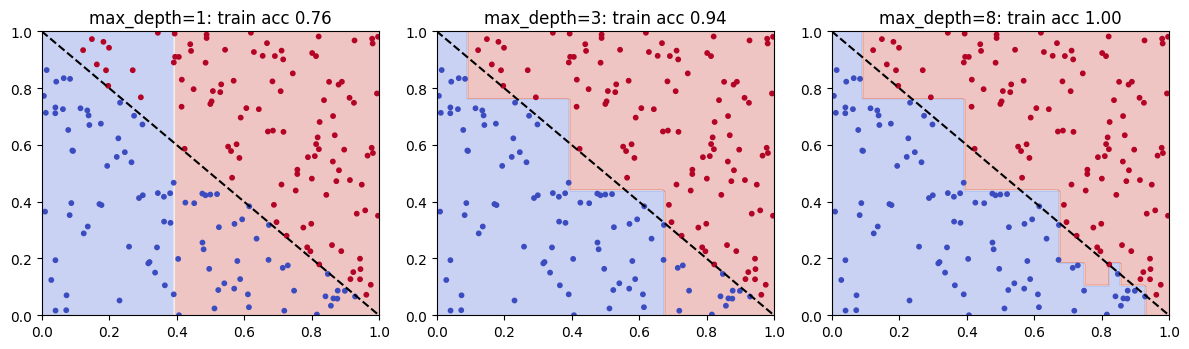

In [2]:
rng = np.random.default_rng(0)
X_toy = rng.random((200, 2))
y_toy = (X_toy[:, 0] + X_toy[:, 1] > 1).astype(int)


def print_tree(tree, node=0, depth=0, names=None):
    pad = "    " * depth
    if tree.feature[node] < 0:
        print(f"{pad}-> class {tree.value[node].argmax()}   ({tree.n_rows[node]} rows)")
        return
    f = tree.feature[node]
    name = names[f] if names else f"feature {f}"
    print(f"{pad}{name} <= {tree.threshold[node]:.2f} ?")
    print_tree(tree, tree.left[node], depth + 1, names)
    print(f"{pad}else:")
    print_tree(tree, tree.right[node], depth + 1, names)


xx, yy = np.meshgrid(np.linspace(0, 1, 150), np.linspace(0, 1, 150))
grid = np.c_[xx.ravel(), yy.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, depth in zip(axes, [1, 3, 8]):
    toy = trees.DecisionTree(max_depth=depth).fit(X_toy, y_toy, n_classes=2)
    acc = common.accuracy(y_toy, toy.predict(X_toy))
    if depth == 1:
        print_tree(toy, names=["x0", "x1"])
    ax.contourf(xx, yy, toy.predict(grid).reshape(xx.shape), alpha=0.3, cmap="coolwarm")
    ax.scatter(X_toy[:, 0], X_toy[:, 1], c=y_toy, cmap="coolwarm", s=10)
    ax.plot([0, 1], [1, 0], "k--")
    ax.set_title(f"max_depth={depth}: train acc {acc:.2f}")
plt.tight_layout()
plt.show()

## 4. Data and validation split

Same stratified 80/20 split as every model in the project (`common.stratified_split`, seed 42):
image 16,000 train / 4,000 validation, sentiment 9,600 / 2,400. Every hyper-parameter below is chosen
on the validation rows only; the test set is used once, at the end.

No scaling is needed for raw features: a tree compares one feature with a threshold, so scaling a feature
just moves the threshold.

In [3]:
X_image, y_image, X_image_test, image_test_ids = common.load_task("image")
X_sent, y_sent, X_sent_test, sent_test_ids = common.load_task("sentiment")

DATA = {"image": (X_image, y_image), "sentiment": (X_sent, y_sent)}
TEST = {"image": (X_image_test, image_test_ids), "sentiment": (X_sent_test, sent_test_ids)}
N_CLASSES = common.N_CLASSES
TASKS = ["sentiment", "image"]

SPLIT = {}
for task in TASKS:
    X, y = DATA[task]
    train_idx, val_idx = common.stratified_split(y)
    SPLIT[task] = (X[train_idx], y[train_idx], X[val_idx], y[val_idx])
    print(f"{task:<9} train {len(train_idx):6d}  validation {len(val_idx):5d}  features {X.shape[1]}")

sentiment train   9600  validation  2400  features 768
image     train  16000  validation  4000  features 500


## 5. Experiments

`run` trains one tree and records train accuracy, validation accuracy, size and time.
Every result is kept in `results` and saved to `decision_tree/outputs/`.

In [4]:
results = []


def run(task, experiment, features="raw", data=None, **settings):
    X_tr, y_tr, X_va, y_va = data if data is not None else SPLIT[task]
    start = time.time()
    tree = trees.DecisionTree(**settings).fit(X_tr, y_tr, N_CLASSES[task])
    seconds = time.time() - start
    row = {"task": task, "experiment": experiment, "features": features,
           "max_depth": settings.get("max_depth"), "min_samples_split": settings.get("min_samples_split", 2),
           "min_samples_leaf": settings.get("min_samples_leaf", 1), "criterion": settings.get("criterion", "gini"),
           "n_bins": settings.get("n_bins", 64),
           "train_acc": round(common.accuracy(y_tr, tree.predict(X_tr)), 4),
           "val_acc": round(common.accuracy(y_va, tree.predict(X_va)), 4),
           "nodes": tree.n_nodes, "leaves": tree.n_leaves, "depth": tree.depth(), "seconds": round(seconds, 2)}
    results.append(row)
    return row


def plot_curve(rows, x, title, xlabel, ax):
    labels = [str(r[x]) for r in rows]
    ax.plot(labels, [r["train_acc"] for r in rows], marker="o", label="train")
    ax.plot(labels, [r["val_acc"] for r in rows], marker="o", label="validation")
    best = max(rows, key=lambda r: r["val_acc"])
    ax.axvline(labels.index(str(best[x])), color="grey", ls=":", lw=1)
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel("accuracy"); ax.grid(alpha=0.3); ax.legend()


def show(rows, cols=("train_acc", "val_acc", "nodes", "depth", "seconds")):
    keys = [k for k in rows[0] if k not in ("task", "experiment", "features", "train_acc", "val_acc",
                                             "nodes", "leaves", "depth", "seconds")]
    varying = [k for k in keys if len({str(r[k]) for r in rows}) > 1]
    return pd.DataFrame(rows)[["task"] + varying + list(cols)]

### 5.1 Maximum depth — under-fitting vs over-fitting

* A shallow tree asks too few questions → train and validation accuracy are both low (**under-fitting**).
* A very deep tree keeps splitting until leaves are pure → train accuracy goes to 1.0 while validation
  accuracy stops improving or drops (**over-fitting**: the last questions only memorise noise).

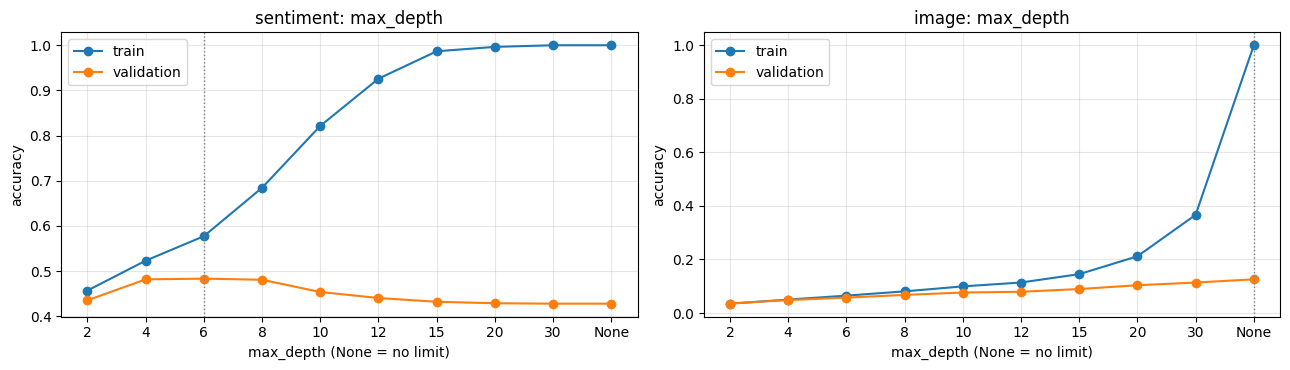

,task,max_depth,train_acc,val_acc,nodes,depth,seconds
0,sentiment,2.0,0.4570,0.4354,7,2,0.53
1,sentiment,4.0,0.5231,0.4817,31,4,0.60
2,sentiment,6.0,0.5773,0.4833,127,6,0.76
3,sentiment,8.0,0.6845,0.4808,479,8,1.20
4,sentiment,10.0,0.8215,0.4537,1259,10,2.10
5,sentiment,12.0,0.9260,0.4404,2059,12,3.02
6,sentiment,15.0,0.9867,0.4321,2729,15,3.77
7,sentiment,20.0,0.9964,0.4288,2879,20,3.98
8,sentiment,30.0,1.0000,0.4279,2963,29,4.12
9,sentiment,NaN,1.0000,0.4279,2963,29,4.09


In [5]:
DEPTHS = [2, 4, 6, 8, 10, 12, 15, 20, 30, None]
depth_rows = {}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, task in zip(axes, TASKS):
    depth_rows[task] = [run(task, "max_depth", max_depth=d) for d in DEPTHS]
    plot_curve(depth_rows[task], "max_depth", f"{task}: max_depth", "max_depth (None = no limit)", ax)
plt.tight_layout(); plt.show()
pd.concat([show(depth_rows[t]) for t in TASKS])

### 5.2 Minimum rows to split a node, and minimum rows in a leaf

Both stop the tree from making questions based on very few rows (a form of **pre-pruning**).
We use no depth limit here, so these are the only brakes on the tree.

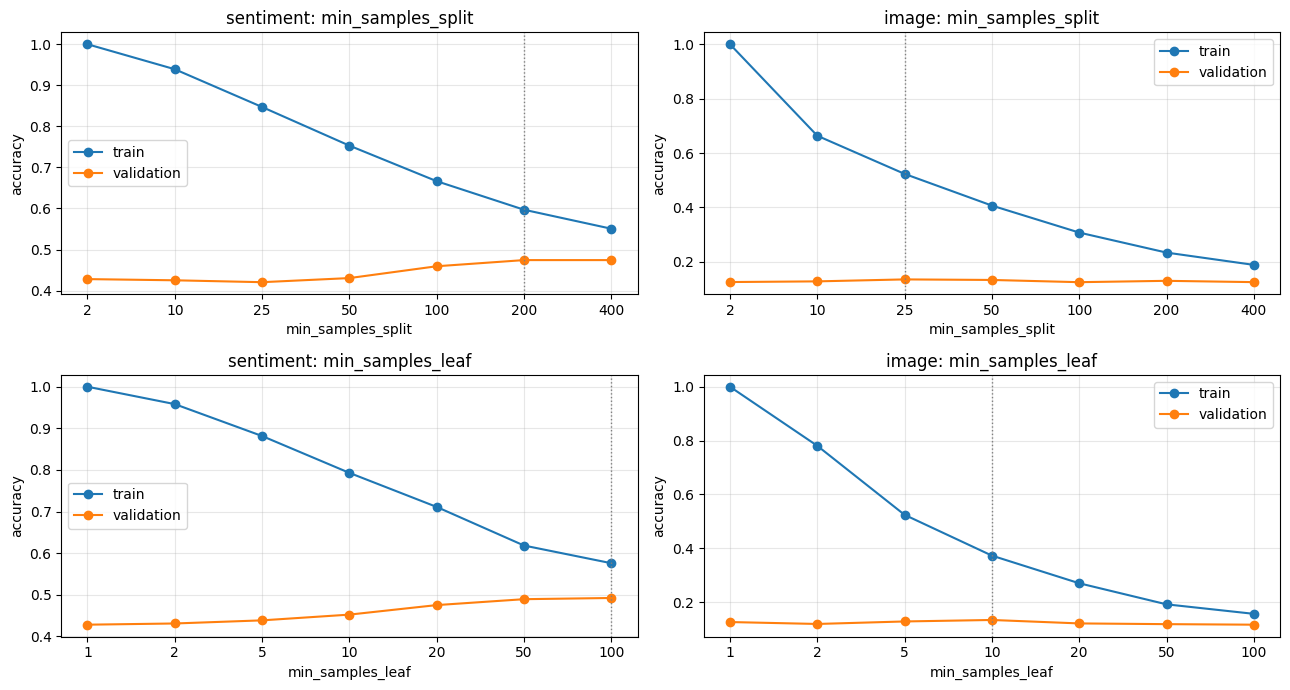

,task,min_samples_split,train_acc,val_acc,nodes,depth,seconds
0,sentiment,2,1.0000,0.4279,2963,29,3.87
1,sentiment,10,0.9391,0.4250,2091,28,2.94
2,sentiment,25,0.8471,0.4204,1451,28,2.26
3,sentiment,50,0.7530,0.4304,951,28,1.69
4,sentiment,100,0.6664,0.4592,539,28,1.23
5,sentiment,200,0.5969,0.4742,245,25,0.87
6,sentiment,400,0.5506,0.4742,95,9,0.67
0,image,2,1.0000,0.1258,17801,129,65.61
1,image,10,0.6636,0.1283,7569,125,28.63
2,image,25,0.5234,0.1355,4639,120,17.90


,task,min_samples_leaf,train_acc,val_acc,nodes,depth,seconds
0,sentiment,1,1.0000,0.4279,2963,29,3.91
1,sentiment,2,0.9582,0.4308,2603,25,3.52
2,sentiment,5,0.8815,0.4383,1879,21,2.74
3,sentiment,10,0.7929,0.4521,1211,17,2.00
4,sentiment,20,0.7110,0.4750,701,15,1.40
5,sentiment,50,0.6182,0.4892,297,12,0.93
6,sentiment,100,0.5757,0.4921,147,8,0.74
0,image,1,1.0000,0.1258,17801,129,66.26
1,image,2,0.7806,0.1187,11913,126,44.81
2,image,5,0.5241,0.1280,5097,105,19.35


In [6]:
SPLITS = [2, 10, 25, 50, 100, 200, 400]
LEAVES = [1, 2, 5, 10, 20, 50, 100]
split_rows, leaf_rows = {}, {}
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for col, task in enumerate(TASKS):
    split_rows[task] = [run(task, "min_samples_split", min_samples_split=s) for s in SPLITS]
    leaf_rows[task] = [run(task, "min_samples_leaf", min_samples_leaf=l) for l in LEAVES]
    plot_curve(split_rows[task], "min_samples_split", f"{task}: min_samples_split", "min_samples_split", axes[0, col])
    plot_curve(leaf_rows[task], "min_samples_leaf", f"{task}: min_samples_leaf", "min_samples_leaf", axes[1, col])
plt.tight_layout(); plt.show()
display(pd.concat([show(split_rows[t]) for t in TASKS]))
display(pd.concat([show(leaf_rows[t]) for t in TASKS]))

### 5.3 Splitting criterion: Gini vs entropy

We compare both criteria at the best depth and the best leaf size found above.

In [7]:
def best_of(rows):
    return max(rows, key=lambda r: r["val_acc"])

crit_rows = []
for task in TASKS:
    d = best_of(depth_rows[task])["max_depth"]
    l = best_of(leaf_rows[task])["min_samples_leaf"]
    for crit in ["gini", "entropy"]:
        crit_rows.append(run(task, "criterion", max_depth=d, criterion=crit))
        crit_rows.append(run(task, "criterion", min_samples_leaf=l, criterion=crit))
show(crit_rows)

,task,max_depth,min_samples_leaf,criterion,train_acc,val_acc,nodes,depth,seconds
0,sentiment,6.0,1,gini,0.5773,0.4833,127,6,0.71
1,sentiment,NaN,100,gini,0.5757,0.4921,147,8,0.74
2,sentiment,6.0,1,entropy,0.5609,0.4833,125,6,0.74
3,sentiment,NaN,100,entropy,0.5609,0.4929,151,10,0.80
4,image,NaN,1,gini,1.0000,0.1258,17801,129,65.19
5,image,NaN,10,gini,0.3726,0.1335,2543,78,10.14
6,image,NaN,1,entropy,1.0000,0.0988,18869,47,149.43
7,image,NaN,10,entropy,0.3094,0.0993,2449,39,19.93


### 5.4 Combining depth and leaf size

The two brakes interact, so we try a small grid around the best single values.

In [8]:
grid_rows = []
GRID = {"sentiment": ([4, 5, 6, 8, None], [1, 10, 20, 50, 100]),
        "image": ([15, 20, 30, None], [1, 5, 10, 20, 50])}
for task in TASKS:
    depths, leaves = GRID[task]
    for d in depths:
        for l in leaves:
            grid_rows.append(run(task, "depth x leaf", max_depth=d, min_samples_leaf=l))
g = pd.DataFrame(grid_rows)
for task in TASKS:
    print(task, "- validation accuracy (rows = max_depth, columns = min_samples_leaf)")
    display(g[g.task == task].pivot_table(index="max_depth", columns="min_samples_leaf",
                                         values="val_acc", dropna=False).round(4))

sentiment - validation accuracy (rows = max_depth, columns = min_samples_leaf)


min_samples_leaf,1,10,20,50,100
max_depth,,,,,
4.0,0.4817,0.4817,0.4817,0.4817,0.4813
5.0,0.4763,0.4763,0.4763,0.4767,0.4800
6.0,0.4833,0.4821,0.4850,0.4833,0.4858
8.0,0.4808,0.4808,0.4879,0.4917,0.4921
NaN,0.4279,0.4521,0.4750,0.4892,0.4921


image - validation accuracy (rows = max_depth, columns = min_samples_leaf)


min_samples_leaf,1,5,10,20,50
max_depth,,,,,
15.0,0.0895,0.0902,0.0943,0.0917,0.0910
20.0,0.1037,0.1080,0.1087,0.1075,0.1052
30.0,0.1138,0.1190,0.1215,0.1140,0.1125
NaN,0.1258,0.1280,0.1335,0.1207,0.1180


### 5.5 Implementation choice: number of candidate thresholds, and zero-aware binning

`n_bins` = how many candidate thresholds each feature gets (+1). Few bins → coarse questions; many bins →
finer questions but slower. We also compare against the **plain-quantile binner** used in our first version
(which, on the image data, places most thresholds at 0).

In [9]:
class PlainQuantileBinner(trees.Binner):
    """Our first version: thresholds = plain quantiles of each feature (no non-zero quantiles)."""
    def fit(self, X):
        q = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        self.thresholds = np.quantile(X, q, axis=0).T
        self.max_t = self.thresholds.shape[1]
        return self


bin_rows = []
for task in TASKS:
    l = best_of(leaf_rows[task])["min_samples_leaf"]
    for nb in [8, 16, 32, 64, 128, 256]:
        bin_rows.append(run(task, "n_bins", min_samples_leaf=l, n_bins=nb))
show(bin_rows)

,task,min_samples_leaf,n_bins,train_acc,val_acc,nodes,depth,seconds
0,sentiment,100,8,0.5579,0.4817,141,8,0.47
1,sentiment,100,16,0.5720,0.4725,149,9,0.55
2,sentiment,100,32,0.5724,0.4746,147,9,0.65
3,sentiment,100,64,0.5757,0.4921,147,8,0.81
4,sentiment,100,128,0.5736,0.4908,141,9,0.95
5,sentiment,100,256,0.5786,0.4708,145,9,1.32
6,image,10,8,0.3571,0.1192,2469,71,2.01
7,image,10,16,0.3648,0.1138,2527,75,3.05
8,image,10,32,0.3726,0.1273,2569,74,5.39
9,image,10,64,0.3726,0.1335,2543,78,10.45


In [10]:
X_tr, y_tr, X_va, y_va = SPLIT["image"]
plain = PlainQuantileBinner(64).fit(X_tr)
ours = trees.Binner(64).fit(X_tr)
distinct_plain = np.mean([len(np.unique(t)) for t in plain.thresholds])
distinct_ours = np.mean([np.isfinite(t).sum() for t in ours.thresholds])
print(f"image: distinct thresholds per feature  plain quantiles {distinct_plain:.1f}   ours {distinct_ours:.1f}")

l = best_of(leaf_rows["image"])["min_samples_leaf"]
for name, binner in [("plain quantiles", plain), ("zero-aware (ours)", ours)]:
    tree = trees.DecisionTree(min_samples_leaf=l).fit(X_tr, y_tr, 50, binner=binner)
    print(f"   {name:<18} validation accuracy {common.accuracy(y_va, tree.predict(X_va)):.4f}")

image: distinct thresholds per feature  plain quantiles 10.0   ours 63.0


   plain quantiles    validation accuracy 0.1148


   zero-aware (ours)  validation accuracy 0.1335


### 5.6 Representation: raw features vs LDA projection

A tree cuts along **one feature at a time** (section 3). If the classes are separated by a *combination*
of many features (likely for 768 BERT dimensions), a tree needs a long staircase of cuts to follow it.

**Linear Discriminant Analysis** (Fisher, `trees.fit_lda`, implemented in NumPy) finds the few directions
that best separate the class means relative to the spread inside each class (at most `classes - 1`
directions: 2 for sentiment, 49 for image). Projecting onto them is a standard dimensionality reduction,
fitted on the **training rows only**. `shrinkage` regularises the within-class covariance
(`(1-s) Sw + s * mean_variance * I`) — useful with 768 correlated features.

We tune `shrinkage` and the tree size on the validation set.

In [11]:
LDA_SPLIT = {}

def lda_data(task, shrinkage):
    key = (task, shrinkage)
    if key not in LDA_SPLIT:
        X_tr, y_tr, X_va, y_va = SPLIT[task]
        lda = trees.fit_lda(X_tr, y_tr, N_CLASSES[task], shrinkage)
        LDA_SPLIT[key] = (trees.apply_lda(X_tr, lda), y_tr, trees.apply_lda(X_va, lda), y_va)
    return LDA_SPLIT[key]


lda_rows = []
SHRINK = [0.0, 0.1, 0.3, 0.5, 0.8]
for task in TASKS:
    for s in SHRINK:
        for d in ([2, 3, 4, 6, 8, None] if task == "sentiment" else [10, 15, 20, None]):
            row = run(task, "lda", features=f"lda s={s}", data=lda_data(task, s),
                      max_depth=d, min_samples_leaf=20)
            row["shrinkage"] = s
            lda_rows.append(row)
l = pd.DataFrame(lda_rows)
for task in TASKS:
    print(task, "- validation accuracy on LDA features (rows = shrinkage, columns = max_depth, min_samples_leaf = 20)")
    display(l[l.task == task].pivot_table(index="shrinkage", columns="max_depth", values="val_acc", dropna=False).round(4))

sentiment - validation accuracy on LDA features (rows = shrinkage, columns = max_depth, min_samples_leaf = 20)


max_depth,2.0,3.0,4.0,6.0,8.0,NaN
shrinkage,,,,,,
0.0,0.6129,0.6346,0.6396,0.6529,0.6517,0.6475
0.1,0.6596,0.6683,0.6637,0.6675,0.6658,0.6575
0.3,0.6625,0.6683,0.6650,0.6654,0.6692,0.6633
0.5,0.6529,0.6650,0.6629,0.6687,0.6596,0.6546
0.8,0.6471,0.6512,0.6512,0.6529,0.6508,0.6412


image - validation accuracy on LDA features (rows = shrinkage, columns = max_depth, min_samples_leaf = 20)


max_depth,10.0,15.0,20.0,NaN
shrinkage,,,,
0.0,0.1390,0.1610,0.1620,0.1633
0.1,0.1400,0.1620,0.1590,0.1593
0.3,0.1378,0.1615,0.1638,0.1648
0.5,0.1425,0.1638,0.1645,0.1678
0.8,0.1370,0.1547,0.1590,0.1588


Sentiment with LDA has only **2 features**, so a shallow tree can be printed and read.
Each question is a threshold on one of the two discriminant directions.

LD1 <= 0.27 ?
    LD2 <= -0.23 ?
        -> class 1   (2570 rows)
    else:
        -> class 2   (2980 rows)
else:
    LD2 <= -0.98 ?
        -> class 1   (610 rows)
    else:
        -> class 0   (3440 rows)
validation accuracy of this 3-question tree: 0.6625


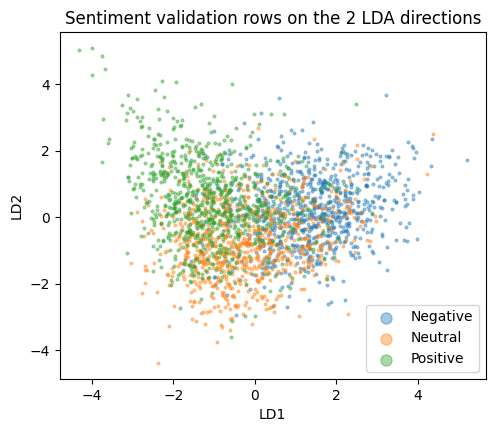

In [12]:
best_sent_lda = max([r for r in lda_rows if r["task"] == "sentiment"], key=lambda r: r["val_acc"])
X_tr, y_tr, X_va, y_va = lda_data("sentiment", best_sent_lda["shrinkage"])
small = trees.DecisionTree(max_depth=2).fit(X_tr, y_tr, 3)
print_tree(small, names=["LD1", "LD2"])
print("validation accuracy of this 3-question tree:", round(common.accuracy(y_va, small.predict(X_va)), 4))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for c, name in enumerate(common.SENTIMENT_NAMES):
    m = y_va == c
    ax.scatter(X_va[m, 0], X_va[m, 1], s=4, alpha=0.4, label=name)
ax.set_xlabel("LD1"); ax.set_ylabel("LD2"); ax.set_title("Sentiment validation rows on the 2 LDA directions")
ax.legend(markerscale=4); plt.show()

## 6. All results and the selected tree per task

We select, for each task, the configuration with the best **validation** accuracy.

In [13]:
table = pd.DataFrame(results)
for task in TASKS:
    t = table[table.task == task].sort_values("val_acc", ascending=False)
    t.to_csv(f"decision_tree/outputs/{task}_experiments.csv", index=False)

best = {}
for task in TASKS:
    candidates = [r for r in results if r["task"] == task]
    best[task] = max(candidates, key=lambda r: r["val_acc"])
summary = pd.DataFrame([best[t] for t in TASKS])
summary[["task", "features", "max_depth", "min_samples_split", "min_samples_leaf", "criterion", "n_bins",
         "train_acc", "val_acc", "nodes", "depth", "seconds"]]

,task,features,max_depth,min_samples_split,min_samples_leaf,criterion,n_bins,train_acc,val_acc,nodes,depth,seconds
0,sentiment,lda s=0.3,8.0,2,20,gini,64,0.7252,0.6692,339,8,0.01
1,image,lda s=0.5,NaN,2,20,gini,64,0.3412,0.1678,1217,25,0.53


## 7. Error analysis of the selected trees

We retrain the selected tree and look at **which** classes it gets wrong:
* sentiment: confusion matrix, precision / recall / F1 per class
* image: hardest classes and the most frequent (true → predicted) confusions

In [14]:
def settings_of(row):
    return dict(max_depth=None if pd.isna(row["max_depth"]) else int(row["max_depth"]),
                min_samples_split=int(row["min_samples_split"]), min_samples_leaf=int(row["min_samples_leaf"]),
                criterion=row["criterion"], n_bins=int(row["n_bins"]))


def shrinkage_of(row):
    return float(row["features"].split("=")[1]) if row["features"].startswith("lda") else None


def per_class_table(y_true, y_pred, n_classes, names=None):
    cm = common.confusion_matrix(y_true, y_pred, n_classes)
    p, r = common.per_class_precision(cm), common.per_class_recall(cm)
    f1 = np.where(p + r > 0, 2 * p * r / np.maximum(p + r, 1e-12), 0)
    return cm, pd.DataFrame({"precision": p, "recall": r, "f1": f1},
                            index=names if names else range(n_classes)).round(3)


final_trees, val_pred = {}, {}
for task in TASKS:
    row = best[task]
    s = shrinkage_of(row)
    X_tr, y_tr, X_va, y_va = SPLIT[task] if s is None else lda_data(task, s)
    tree = trees.DecisionTree(**settings_of(row)).fit(X_tr, y_tr, N_CLASSES[task])
    final_trees[task] = tree
    val_pred[task] = tree.predict(X_va)
    np.save(f"decision_tree/outputs/{task}_val_pred.npy", val_pred[task])     # used by final/compare.ipynb
    np.save(f"decision_tree/outputs/{task}_val_proba.npy", tree.predict_proba(X_va))
    print(f"{task}: features={row['features']}  {settings_of(row)}  validation accuracy "
          f"{common.accuracy(y_va, val_pred[task]):.4f}")

y_va = SPLIT["sentiment"][3]
cm, per_class = per_class_table(y_va, val_pred["sentiment"], 3, common.SENTIMENT_NAMES)
print("\nSentiment confusion matrix (rows = true, columns = predicted)")
display(pd.DataFrame(cm, index=common.SENTIMENT_NAMES, columns=common.SENTIMENT_NAMES))
display(per_class)

sentiment: features=lda s=0.3  {'max_depth': 8, 'min_samples_split': 2, 'min_samples_leaf': 20, 'criterion': 'gini', 'n_bins': 64}  validation accuracy 0.6692


image: features=lda s=0.5  {'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 20, 'criterion': 'gini', 'n_bins': 64}  validation accuracy 0.1678

Sentiment confusion matrix (rows = true, columns = predicted)


,Negative,Neutral,Positive
Negative,609,130,61
Neutral,175,452,173
Positive,90,165,545


,precision,recall,f1
Negative,0.697,0.761,0.728
Neutral,0.605,0.565,0.584
Positive,0.700,0.681,0.690


Image: 5 hardest and 5 easiest classes (by recall)


,precision,recall,f1
19,0.000,0.000,0.000
29,0.025,0.012,0.017
9,0.015,0.012,0.014
0,0.026,0.025,0.026
31,0.049,0.025,0.033
13,0.384,0.412,0.398
28,0.330,0.438,0.376
5,0.594,0.475,0.528
48,0.704,0.475,0.567
46,0.725,0.625,0.671


Most frequent confusions (true class -> predicted class, count out of 80):
    4 ->  2   17
    3 ->  2   13
   25 -> 12   13
   11 -> 28   9
   14 -> 12   9
   22 -> 42   9
    2 ->  4   8
    9 ->  8   8


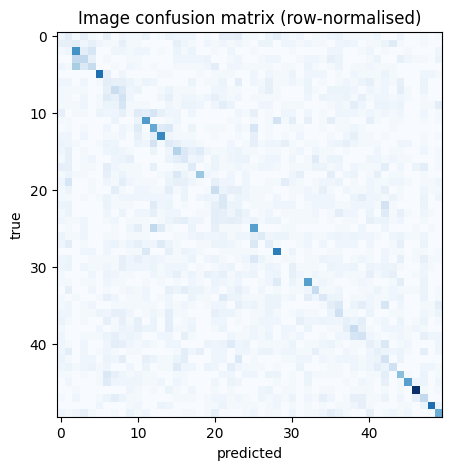

In [15]:
y_va = SPLIT["image"][3]
cm, per_class = per_class_table(y_va, val_pred["image"], 50)
print("Image: 5 hardest and 5 easiest classes (by recall)")
display(pd.concat([per_class.sort_values("recall").head(5), per_class.sort_values("recall").tail(5)]))
print("Most frequent confusions (true class -> predicted class, count out of 80):")
for t, p, n in common.most_confused_pairs(cm, 8):
    print(f"   {t:2d} -> {p:2d}   {n}")

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm / cm.sum(1, keepdims=True), cmap="Blues")
ax.set_title("Image confusion matrix (row-normalised)"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.show()

### Which features does the tree use?

Feature importance = total row-weighted impurity decrease of the splits on each feature.

In [16]:
for task in TASKS:
    tree = final_trees[task]
    n_feat = tree.binner.thresholds.shape[0]
    imp = tree.feature_importance(n_feat)
    top = np.argsort(imp)[::-1][:10]
    used = (imp > 0).sum()
    print(f"{task}: the tree uses {used} of {n_feat} features; top-10 features carry {imp[top].sum():.0%} of the importance")
    print("   ", ", ".join(f"{f} ({imp[f]:.2f})" for f in top))

sentiment: the tree uses 2 of 2 features; top-10 features carry 100% of the importance
    0 (0.62), 1 (0.38)
image: the tree uses 49 of 49 features; top-10 features carry 52% of the importance
    0 (0.10), 4 (0.06), 2 (0.06), 7 (0.05), 8 (0.05), 3 (0.05), 5 (0.04), 11 (0.04), 6 (0.04), 9 (0.03)


## 8. Test predictions for Kaggle

Same settings, retrained on **all** training rows (train + validation). If LDA was selected, the LDA
projection is also re-fitted on all training rows before projecting the test rows.

In [17]:
for task in TASKS:
    row = best[task]
    X, y = DATA[task]
    X_test, test_ids = TEST[task]
    s = shrinkage_of(row)
    if s is not None:
        lda = trees.fit_lda(X, y, N_CLASSES[task], s)
        X, X_test = trees.apply_lda(X, lda), trees.apply_lda(X_test, lda)
    start = time.time()
    tree = trees.DecisionTree(**settings_of(row)).fit(X, y, N_CLASSES[task])
    fit_s = time.time() - start
    start = time.time()
    pred = tree.predict(X_test)
    pd.DataFrame({"id": test_ids, "label": pred}).to_csv(f"decision_tree/outputs/{task}_test_pred.csv", index=False)
    print(f"{task}: saved decision_tree/outputs/{task}_test_pred.csv   train {fit_s:.1f}s, predict {time.time() - start:.2f}s, "
          f"{tree.n_nodes} nodes, test class counts {np.bincount(pred, minlength=N_CLASSES[task])[:10]}...")

sentiment: saved decision_tree/outputs/sentiment_test_pred.csv   train 0.0s, predict 0.00s, 361 nodes, test class counts [2289 1408 1303]...


image: saved decision_tree/outputs/image_test_pred.csv   train 0.7s, predict 0.00s, 1499 nodes, test class counts [132 100  91 105 161  81 126 108 145 119]...


## 9. Findings (filled in from the outputs above — see the report)

* **Depth:** on both tasks train accuracy rises to 1.0 with depth while validation accuracy peaks early
  and then falls → a deep tree **over-fits**; a very shallow tree **under-fits**.
* **Pre-pruning:** `min_samples_leaf` / `min_samples_split` give the same effect as a depth limit and are
  a smoother brake; criterion (Gini vs entropy) makes little difference.
* **Image task (50 classes):** a single tree is weak. Each leaf must separate 50 classes using one
  feature per question, the features are sparse (85% zeros) and the evidence for a class is spread over
  many weak features.
* **Sentiment task:** the classes are separated by a *direction* that mixes many BERT features. A tree on
  raw features needs a staircase of cuts; after an LDA projection a very small tree is competitive.
* **Implementation:** zero-aware thresholds matter for sparse features; histogram split search makes a
  full image tree train in seconds instead of minutes.